In [1]:
import json
import os

from IPython.display import Image, Markdown, display


def load(name):
    with open(os.path.join("parts", name + ".json")) as file:
        return json.load(file)


def cell(value, form):
    if value is None:
        return "—"
    if callable(form):
        return form(value)
    return format(value, form) if form else str(value)


def table(rows, columns):
    """columns: (header, a key or a function of the row, a format spec or a function)"""
    def value(row, pick):
        return pick(row) if callable(pick) else row.get(pick)
    lines = ["| " + " | ".join(header for header, _, _ in columns) + " |",
             "|" + "---|" * len(columns)]
    for row in rows:
        lines.append("| " + " | ".join(cell(value(row, pick), form) for _, pick, form in columns) + " |")
    display(Markdown("\n".join(lines)))


def figure(path):
    display(Image(filename=path, width=720))

# EP4 comparison: NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 16:54) vs NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 17:06)

**What this is.** The measurements of several machines side by side, read from their own folders (listed below).
Each one ran the same `measure` with the same engine code.

In [2]:
data = load("comparison")
table(data["machines"], [("machine", "name", None), ("SMs", "sms", None), ("cc", "cc", None),
                         ("threads/SM", "threads_per_sm", None), ("registers/SM", "registers_per_sm", None),
                         ("code", "code", None), ("driver", "driver", None), ("folder", "folder", None)])

| machine | SMs | cc | threads/SM | registers/SM | code | driver | folder |
|---|---|---|---|---|---|---|---|
| NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 16:54) | 36 | 120 | 1536 | 65536 | 72b86b63cbf7 | 621.14 | measure/2026-11-22_16-54-40-Welton-all |
| NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 17:06) | 36 | 120 | 1536 | 65536 | 72b86b63cbf7 | 621.14 | measure/2026-11-22_17-06-33-Welton-validation-devices-kernel |

## Speed

Photons per second on all SMs (the photon phase); per SM; and per SM per GHz, which removes the number of SMs and the
clock and leaves what one SM does per cycle.

| machine | FP | photons/s | per SM | per SM per GHz | clock (MHz) | power (W) | power cap | one CPU core |
|---|---|---|---|---|---|---|---|---|
| NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 16:54) | 64 | 6.11e+08 | 1.7e+07 | 6.09e+06 | 2786 | 38 | 0% | 8.83e+06 |
| NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 16:54) | 32 | 1.01e+10 | 2.8e+08 | 1.08e+08 | 2596 | 112 | 78% | 1.37e+07 |
| NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 17:06) | 64 | 6.44e+08 | 1.79e+07 | 6.22e+06 | 2877 | 38 | 0% | 9.29e+06 |
| NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 17:06) | 32 | 1.08e+10 | 3.01e+08 | 1.11e+08 | 2724 | 74 | 75% | 1.4e+07 |

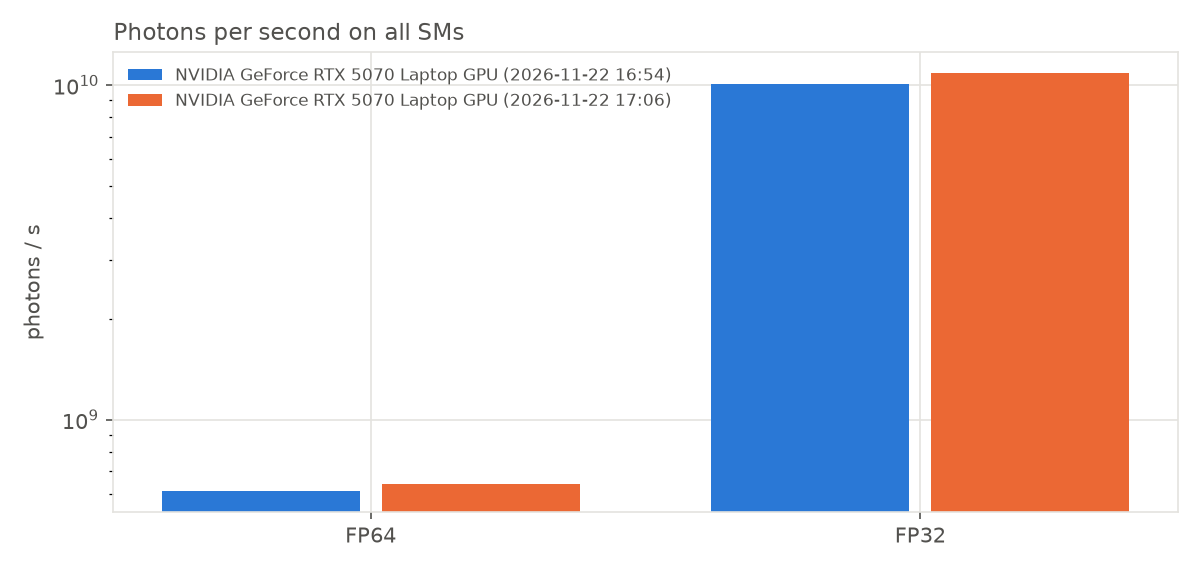

In [3]:
table(data["speeds"], [("machine", "machine", None), ("FP", "precision", None),
                       ("photons/s", "photons_per_second", ".3g"), ("per SM", "per_sm", ".3g"),
                       ("per SM per GHz", "per_sm_per_ghz", ".3g"), ("clock (MHz)", "clock_mhz", ".0f"),
                       ("power (W)", "power_w", ".0f"), ("power cap", "power_cap_share", ".0%"),
                       ("one CPU core", "cpu_core", ".3g")])
figure("figures/speeds.png")

**What it means.**
- NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 17:06) vs NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 16:54), FP64: 1.05× the photons per second; per SM per GHz 1.02×
- NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 17:06) vs NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 16:54), FP32: 1.08× the photons per second; per SM per GHz 1.03×

## Scaling

| machine | FP | SMs | strong speedup | Amdahl p (photons) | Amdahl p (whole run) | speedup in cycles | weak efficiency | Gustafson s′ |
|---|---|---|---|---|---|---|---|---|
| NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 16:54) | 64 | 36 | 35.6 | 0.9999 | 0.9953 | 35.7 | 0.990 | 0.1546 |
| NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 16:54) | 32 | 36 | 33.2 | 0.9992 | 0.9931 | 35.6 | 0.917 | 0.2168 |

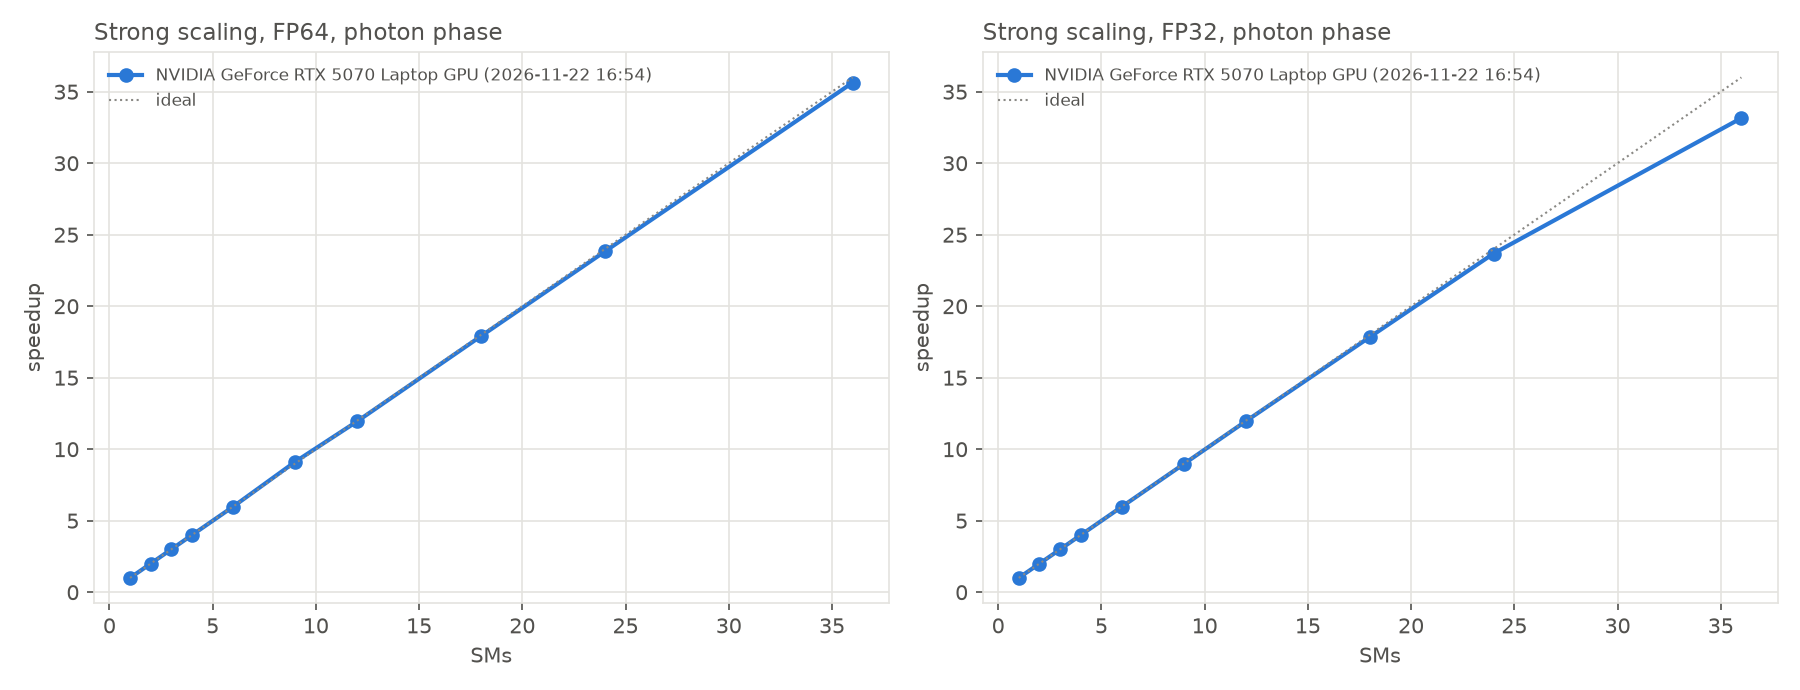

In [4]:
table(data["scaling"], [("machine", "machine", None), ("FP", "precision", None), ("SMs", "sms", None),
                        ("strong speedup", "strong_speedup", ".1f"), ("Amdahl p (photons)", "strong_p", ".4f"),
                        ("Amdahl p (whole run)", "whole_p", ".4f"), ("speedup in cycles", "cycles_speedup", ".1f"),
                        ("weak efficiency", "weak_efficiency", ".3f"), ("Gustafson s′", "s_prime", ".4f")])
figure("figures/strong.png")

## Registers and occupancy

| machine | precision | registers | occupancy | fewest cycles at | its occupancy | its cycles vs uncapped |
|---|---|---|---|---|---|---|
| NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 16:54) | fp64 | 80 | 0.50 | 72 | 0.58 | 0.998 |
| NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 16:54) | fp32 | 67 | 0.58 | 67 | 0.58 | 1.000 |

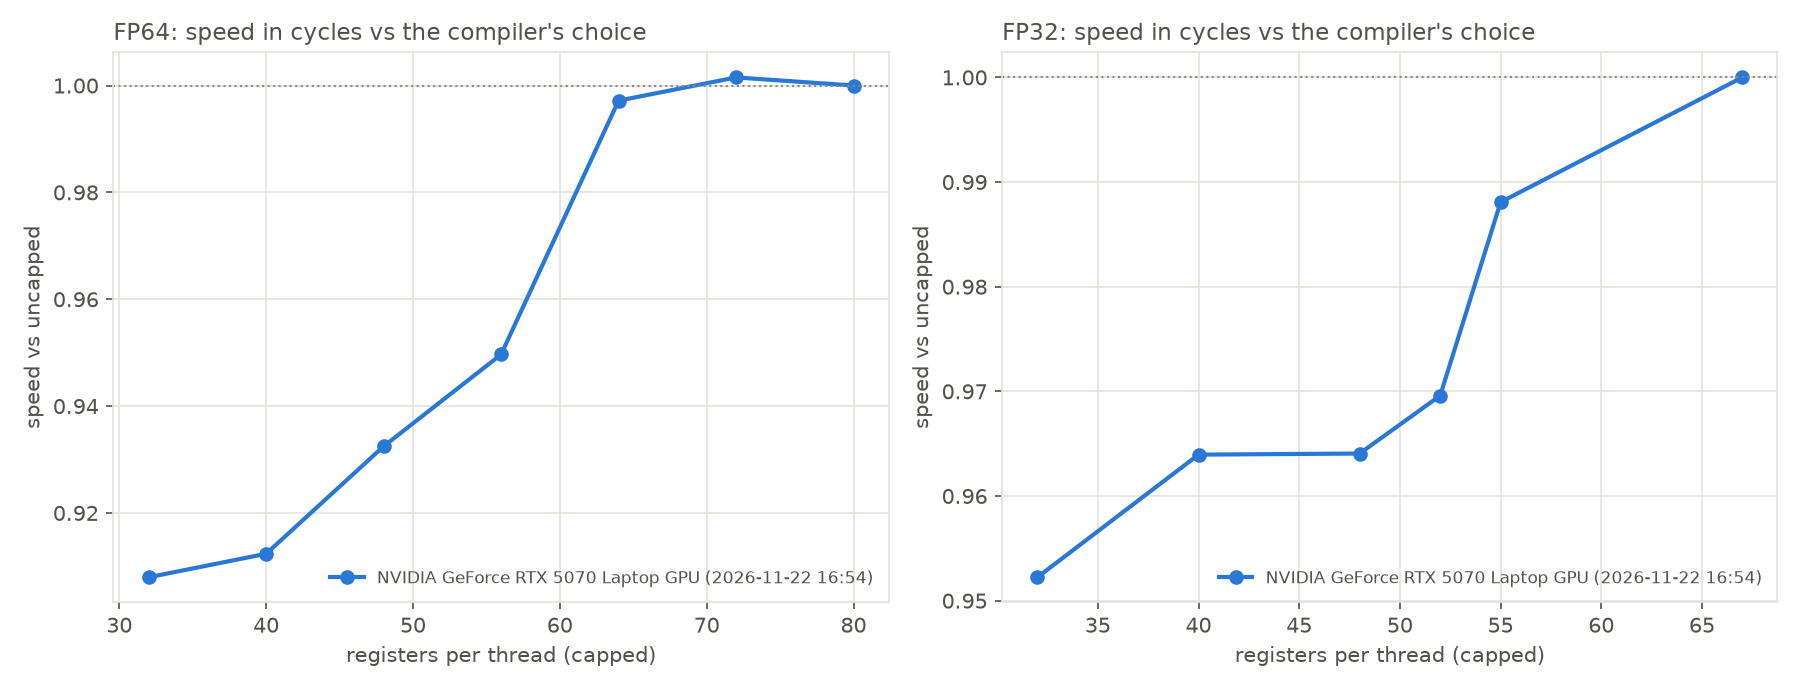

In [5]:
table(data["occupancy"], [("machine", "machine", None), ("precision", "precision", None),
                          ("registers", "registers", None), ("occupancy", "occupancy", ".2f"),
                          ("fewest cycles at", "best_registers", None), ("its occupancy", "best_occupancy", ".2f"),
                          ("its cycles vs uncapped", "best_cycles", ".3f")])
figure("figures/occupancy.png")

## The same images?

A fixed run (N = 10⁸, the default star) on each machine, its images hashed. Identical hashes mean identical images, bit for bit.

- cpu64: identical; gpu32: identical; gpu64: identical

In [6]:
table(data["digests"], [("binary", "binary", None)] + [(m["name"], m["name"], None) for m in data["machines"]]
      + [("identical", "identical", lambda v: "yes" if v else "NO")])

| binary | NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 16:54) | NVIDIA GeForce RTX 5070 Laptop GPU (2026-11-22 17:06) | identical |
|---|---|---|---|
| cpu64 | ee9af07f55ed409a | ee9af07f55ed409a | yes |
| gpu32 | 4829b43062c435b8 | 4829b43062c435b8 | yes |
| gpu64 | ee9af07f55ed409a | ee9af07f55ed409a | yes |